# AML 02 — Variable and Entity Extraction (NER)

This notebook investigates Named Entity Recognition (NER) as a tool for identifying and analysing variables and entities in the **Corr2Cause** causal-reasoning benchmark. It builds on the data preparation and feature engineering work from [`AML_01_data_features.ipynb`](AML_01_data_features.ipynb).

### Sections
1. **Configuration and Imports** — paths, constants, shared utilities from AML_01.
2. **Data Loading** — load feature-enriched CSVs if available; fall back gracefully.
3. **Dataset Inspection** — examine representative examples; understand text conventions.
4. **Why Standard NER May Not Fit** — analysis of dataset's abstract variable system.
5. **Rule-Based Symbolic Entity Extraction** — baseline using dataset text conventions.
6. **General-Purpose NER Baseline** — spaCy `en_core_web_sm` (if installed).
7. **Approach Comparison** — entity counts, coverage, agreement, and disagreement examples.
8. **Premise-Hypothesis Consistency Analysis** — variable overlap checks.
9. **Visualisations** — entity type distribution, variable count distribution, coverage plots.
10. **Export** — save NER outputs to `data/processed/`.
11. **Quality Checks** — assertions verifying output schema, serialisation, and no label leakage.
12. **Summary and Conclusions** — methods, limitations, downstream integration notes.

### Objective
Evaluate whether NER — both rule-based and pretrained — is useful for extracting candidate causal entities from Corr2Cause premises and hypotheses, and provide structured entity annotations for the downstream `AML_03_dependency_patterns.ipynb` notebook.

### Task Description
The Corr2Cause dataset frames causal reasoning as **natural language inference (NLI)**:
- **Premise**: Correlational and conditional-independence statements about a closed system of symbolic variables (A, B, C, D, E, F).
- **Hypothesis**: A candidate causal relationship between two specific variables.
- **Label**: `1` if the hypothesis is logically entailed by the premise, `0` if refuted.

This is a **binary classification** task; entity extraction is an intermediate representation step, not the final objective.

## 1. Configuration and Imports

We reuse the same path-resolution logic and shared extraction utilities established in `AML_01_data_features.ipynb`. The `find_repo_root()` function works whether this notebook is launched from the repository root or the `AML/` subdirectory.

In [1]:
import json
import re
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ---------------------------------------------------------------------------
# Path resolution — identical to AML_01 (do not modify)
# ---------------------------------------------------------------------------
def find_repo_root():
    """Locate the repository root whether notebook is run from root, AML/, or a subfolder.

    Raises a clear, actionable FileNotFoundError if repository markers are not found.
    """
    current = Path.cwd().resolve()
    for candidate in [current, current.parent, current.parent.parent]:
        if (candidate / "00_setup.ipynb").exists() and (candidate / "data").exists():
            return candidate
        if (candidate / ".git").exists() and (candidate / "AML").exists():
            return candidate
    raise FileNotFoundError(
        f"Could not locate repository root from current working directory: '{current}'.\n"
        "Expected repository markers ('00_setup.ipynb' and 'data/', or '.git/' and 'AML/') "
        "were not found.\n"
        "Please ensure Jupyter was launched from within the 'causal-nlp-reasoning' repository tree."
    )


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
RAW_DIR = DATA_DIR / "raw"

# Input sources (prefer feature-enriched files from AML_01)
TRAIN_VAL_FEATURES_PATH = PROCESSED_DIR / "train_val_features.csv"
TEST_FEATURES_PATH = PROCESSED_DIR / "test_features.csv"
TRAIN_VAL_PATH = PROCESSED_DIR / "train_val.csv"
TEST_PATH = PROCESSED_DIR / "test.csv"

# Output paths for this notebook
NER_TRAIN_VAL_PATH = PROCESSED_DIR / "ner_train_val.csv"
NER_TEST_PATH = PROCESSED_DIR / "ner_test.csv"

# Dataset constants (from 00_setup.ipynb)
EXPECTED_COLUMNS = ["input", "label", "num_variables", "template"]
ORIGINAL_TRAIN_SIZE = 205_734
ORIGINAL_VAL_SIZE = 1_076
EXPECTED_TRAIN_VAL_SIZE = ORIGINAL_TRAIN_SIZE + ORIGINAL_VAL_SIZE  # 206,810
EXPECTED_TEST_SIZE = 1_162

assert REPO_ROOT.exists(), f"Repository root not found: {REPO_ROOT}"
assert DATA_DIR.exists(), f"Data directory not found: {DATA_DIR}"
assert PROCESSED_DIR.exists(), f"Processed data directory not found: {PROCESSED_DIR}"

print(f"Repository root     : {REPO_ROOT}")
print(f"Processed data      : {PROCESSED_DIR}")
print(f"Feature CSV (TV)    : {TRAIN_VAL_FEATURES_PATH} [exists={TRAIN_VAL_FEATURES_PATH.exists()}]")
print(f"Feature CSV (test)  : {TEST_FEATURES_PATH} [exists={TEST_FEATURES_PATH.exists()}]")
print(f"NER output (TV)     : {NER_TRAIN_VAL_PATH}")
print(f"NER output (test)   : {NER_TEST_PATH}")

Repository root     : /Users/ravya/Desktop/project/causal-nlp-reasoning
Processed data      : /Users/ravya/Desktop/project/causal-nlp-reasoning/data/processed
Feature CSV (TV)    : /Users/ravya/Desktop/project/causal-nlp-reasoning/data/processed/train_val_features.csv [exists=False]
Feature CSV (test)  : /Users/ravya/Desktop/project/causal-nlp-reasoning/data/processed/test_features.csv [exists=False]
NER output (TV)     : /Users/ravya/Desktop/project/causal-nlp-reasoning/data/processed/ner_train_val.csv
NER output (test)   : /Users/ravya/Desktop/project/causal-nlp-reasoning/data/processed/ner_test.csv


## 2. Data Loading

We load data with a three-tier fallback strategy:

1. **Preferred**: Load `train_val_features.csv` and `test_features.csv` from `AML_01_data_features.ipynb`. These already contain `premise` and `hypothesis` columns.
2. **Fallback A**: Load `train_val.csv` and `test.csv` from `00_setup.ipynb` and extract `premise`/`hypothesis` using the same parsing logic.
3. **Fallback B**: Download directly from Hugging Face using the `datasets` library.

> **Design note**: We do not reload the full ~206 k–row train+val dataset into working memory for NER processing, as this would be prohibitively slow for a general-purpose NER model and unnecessary for a descriptive analysis. We use the full symbolic rule-based extraction (which is fast) and run general-purpose NER on a representative stratified sample.

In [2]:
# ---------------------------------------------------------------------------
# Premise / Hypothesis extraction (identical to AML_01)
# ---------------------------------------------------------------------------
PREMISE_HYPOTHESIS_PATTERN = re.compile(
    r"^Premise:\s*(.+?)\s*\nHypothesis:\s*(.+)$",
    re.DOTALL
)


def extract_premise_hypothesis(text):
    """Split the input text into premise and hypothesis components.

    Returns (premise, hypothesis) tuple. If the pattern does not match,
    returns (text, '') so no data is silently dropped.
    """
    if not isinstance(text, str) or not text.strip():
        return ("", "")
    match = PREMISE_HYPOTHESIS_PATTERN.match(text)
    if match:
        return match.group(1).strip(), match.group(2).strip()
    return text.strip(), ""


def apply_text_preprocessing(df):
    """Add 'premise' and 'hypothesis' columns if not already present."""
    if "premise" not in df.columns or "hypothesis" not in df.columns:
        extracted = df["input"].apply(extract_premise_hypothesis)
        df["premise"] = extracted.apply(lambda x: x[0])
        df["hypothesis"] = extracted.apply(lambda x: x[1])
    return df


def load_dataset_tier(label):
    """Load train_val or test DataFrame using the three-tier fallback strategy.

    Reliably preserves or reconstructs the 'original_split' marker:
    - Tier 1 (AML_01 feature CSV): already contains 'original_split'
    - Tier 2 (00_setup base CSV): reconstructs split based on documented row counts
    - Tier 3 (Hugging Face datasets): labels split directly from source dataset split

    Parameters
    ----------
    label : str
        Either 'train_val' or 'test'.

    Returns
    -------
    pd.DataFrame, str   DataFrame and a string describing the source used.
    """
    if label == "train_val":
        feature_path = TRAIN_VAL_FEATURES_PATH
        base_path = TRAIN_VAL_PATH
        hf_split = ["train", "validation"]
        expected_size = EXPECTED_TRAIN_VAL_SIZE
    else:
        feature_path = TEST_FEATURES_PATH
        base_path = TEST_PATH
        hf_split = ["test"]
        expected_size = EXPECTED_TEST_SIZE

    # Tier 1: AML_01 feature-enriched CSV
    if feature_path.exists():
        df = pd.read_csv(feature_path)
        df = apply_text_preprocessing(df)
        source = f"AML_01 feature CSV ({feature_path.name})"
        return df, source

    # Tier 2: 00_setup.ipynb base CSV
    if base_path.exists():
        df = pd.read_csv(base_path)
        missing = set(EXPECTED_COLUMNS) - set(df.columns)
        if missing:
            raise ValueError(f"Missing columns in {base_path.name}: {missing}")
        df = apply_text_preprocessing(df)
        if label == "train_val" and len(df) == EXPECTED_TRAIN_VAL_SIZE:
            df["original_split"] = (
                ["train"] * ORIGINAL_TRAIN_SIZE
                + ["validation"] * ORIGINAL_VAL_SIZE
            )
        source = f"00_setup base CSV ({base_path.name})"
        return df, source

    # Tier 3: Hugging Face datasets
    print(f"  ⚠ No local CSV found for '{label}'. Attempting Hugging Face download...")
    try:
        from datasets import load_dataset
        ds = load_dataset("causal-nlp/corr2cause")
        dfs = []
        for split in hf_split:
            split_df = ds[split].to_pandas()
            # Rename HF columns to match project schema
            rename_map = {}
            if "label" not in split_df.columns and "labels" in split_df.columns:
                rename_map["labels"] = "label"
            if rename_map:
                split_df = split_df.rename(columns=rename_map)
            # Reconstruct original_split reliably from dataset split
            if label == "train_val":
                split_df["original_split"] = split
            dfs.append(split_df)
        df = pd.concat(dfs, ignore_index=True)
        df = apply_text_preprocessing(df)
        source = "Hugging Face datasets (causal-nlp/corr2cause)"
        return df, source
    except ImportError:
        raise RuntimeError(
            f"No data available for '{label}'. Neither local CSV files nor the "
            "'datasets' package are available.\n"
            "Please run 00_setup.ipynb first to generate the processed data files, "
            "or install the datasets package: pip install datasets"
        )
    except Exception as e:
        raise RuntimeError(
            f"Failed to load '{label}' from Hugging Face: {e}\n"
            "Please run 00_setup.ipynb first to generate the processed data files."
        )


print("Loading datasets...")
df_train_val, source_tv = load_dataset_tier("train_val")
df_test, source_test = load_dataset_tier("test")

print(f"  train_val : {len(df_train_val):,} rows × {len(df_train_val.columns)} columns  [source: {source_tv}]")
print(f"  test      : {len(df_test):,} rows × {len(df_test.columns)} columns  [source: {source_test}]")
if "original_split" in df_train_val.columns:
    split_counts = df_train_val["original_split"].value_counts().to_dict()
    print(f"  original_split distribution in train_val: {split_counts}")
else:
    print("  ⚠ original_split not reconstructed (will label sample as combined train/validation)")

Loading datasets...
  ⚠ No local CSV found for 'train_val'. Attempting Hugging Face download...


/Users/ravya/my_project/python_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  ⚠ No local CSV found for 'test'. Attempting Hugging Face download...


  train_val : 206,810 rows × 7 columns  [source: Hugging Face datasets (causal-nlp/corr2cause)]
  test      : 1,162 rows × 6 columns  [source: Hugging Face datasets (causal-nlp/corr2cause)]
  original_split distribution in train_val: {'train': 205734, 'validation': 1076}


In [3]:
# ---------------------------------------------------------------------------
# Schema assertions: required columns must be present after loading
# ---------------------------------------------------------------------------
REQUIRED_COLS = ["input", "label", "num_variables", "template", "premise", "hypothesis"]

for split_name, df in [("train_val", df_train_val), ("test", df_test)]:
    missing = set(REQUIRED_COLS) - set(df.columns)
    assert not missing, f"Missing required columns in {split_name}: {missing}"

    # Verify premise/hypothesis are non-empty for all rows
    empty_premise = (df["premise"].isna() | (df["premise"].str.strip() == "")).sum()
    empty_hyp = (df["hypothesis"].isna() | (df["hypothesis"].str.strip() == "")).sum()
    assert empty_premise == 0, f"{empty_premise} empty premises in {split_name}"
    assert empty_hyp == 0, f"{empty_hyp} empty hypotheses in {split_name}"

    # Verify no target label in extraction inputs (label column must exist but be separate)
    assert "label" in df.columns, f"label column missing from {split_name}"

    # Verify expected dimensions
    if split_name == "train_val" and len(df) == EXPECTED_TRAIN_VAL_SIZE:
        print(f"✓ {split_name}: {len(df):,} rows (matches expected {EXPECTED_TRAIN_VAL_SIZE:,})")
    elif split_name == "test" and len(df) == EXPECTED_TEST_SIZE:
        print(f"✓ {split_name}: {len(df):,} rows (matches expected {EXPECTED_TEST_SIZE:,})")
    else:
        print(f"⚠ {split_name}: {len(df):,} rows (expected size mismatch — fallback source may have different splits)")

print("\n✓ Schema validation passed: all required columns present, no empty text fields.")
print("✓ Label column confirmed separate from extraction inputs.")

✓ train_val: 206,810 rows (matches expected 206,810)
✓ test: 1,162 rows (matches expected 1,162)

✓ Schema validation passed: all required columns present, no empty text fields.
✓ Label column confirmed separate from extraction inputs.


## 3. Dataset Inspection

Before applying any NER method, we must understand the text conventions used in Corr2Cause. In particular:
- How are causal variables introduced and referenced?
- What types of relational statements appear in premises?
- How are hypotheses structured?

This inspection directly informs our choice of NER strategy.

In [4]:
print("=" * 70)
print("DATASET INSPECTION — Representative Examples")
print("=" * 70)

# Show one example per num_variables value from the test set
for n_vars in sorted(df_test["num_variables"].unique()):
    sample = df_test[df_test["num_variables"] == n_vars].iloc[0]
    print(f"\n--- {n_vars}-variable system | template: {sample['template']} | label: {sample['label']} ---")
    # Show full premise (it can be very long; cap at 600 chars for display)
    premise_preview = sample["premise"][:600]
    if len(sample["premise"]) > 600:
        premise_preview += " ...[truncated]"
    print(f"PREMISE   : {premise_preview}")
    print(f"HYPOTHESIS: {sample['hypothesis']}")
    print()

DATASET INSPECTION — Representative Examples

--- 2-variable system | template: has_collider | label: 0 ---
PREMISE   : Suppose there is a closed system of 2 variables, A and B. All the statistical relations among these 2 variables are as follows: A correlates with B.
HYPOTHESIS: There exists at least one collider (i.e., common effect) of A and B.


--- 3-variable system | template: has_collider | label: 0 ---
PREMISE   : Suppose there is a closed system of 3 variables, A, B and C. All the statistical relations among these 3 variables are as follows: A correlates with C. B correlates with C. However, A is independent of B.
HYPOTHESIS: There exists at least one collider (i.e., common effect) of B and C.


--- 4-variable system | template: child | label: 0 ---
PREMISE   : Suppose there is a closed system of 4 variables, A, B, C and D. All the statistical relations among these 4 variables are as follows: A correlates with B. A correlates with C. B correlates with C. However, A is independ

In [5]:
# Show one example per hypothesis template to understand template diversity
print("=" * 70)
print("HYPOTHESIS TEMPLATE EXAMPLES")
print("=" * 70)

for template in sorted(df_test["template"].unique()):
    sample = df_test[df_test["template"] == template].iloc[0]
    print(f"\nTemplate: {template!r}")
    print(f"  Hypothesis: {sample['hypothesis']}")

HYPOTHESIS TEMPLATE EXAMPLES

Template: 'child'
  Hypothesis: B directly causes A.

Template: 'has_collider'
  Hypothesis: There exists at least one collider (i.e., common effect) of A and B.

Template: 'has_confounder'
  Hypothesis: There exists at least one confounder (i.e., common cause) of A and B.

Template: 'non-child descendant'
  Hypothesis: A is a cause for B, but not a direct one.

Template: 'non-parent ancestor'
  Hypothesis: B causes something else which causes A.

Template: 'parent'
  Hypothesis: A directly causes B.


## 4. Why Standard NER May Not Fit This Dataset

### The Corr2Cause Variable System

From the inspection above, we can see that Corr2Cause uses **abstract single-letter symbolic variables** (A, B, C, D, E, F). These are introduced in a closed-system declaration:

> *"Suppose there is a closed system of 4 variables, A, B, C and D."*

Relational statements then describe correlations and conditional independences between them:

> *"A correlates with B. A is independent of C given B. ..."*

Hypotheses assert causal relationships between exactly two of these variables:

> *"A directly causes B."* or *"There exists at least one collider of A and B."*

### Limitations of Standard NER Models

General-purpose NER models (e.g., spaCy `en_core_web_sm`, BERT-NER) are trained on real-world text corpora such as news articles and Wikipedia. Their entity taxonomies typically include:

| NER Label | Intended Meaning |
|-----------|------------------|
| `PERSON`  | Named persons    |
| `ORG`     | Organisations    |
| `GPE`     | Countries, cities |
| `DATE`    | Calendar dates   |
| `CARDINAL`| Bare numbers     |

**Key problems** when applying standard NER to Corr2Cause:

1. **Single-letter variables** (A, B, C …) are not named entities in the conventional sense. Standard models will not recognise them as such; they may be labelled `ORG`, `GPE`, or be entirely skipped.
2. **"A" as an article vs. variable**: The word "A" appears both as the English indefinite article (*"A collider"*) and as variable A (*"A directly causes B"*). Standard models cannot reliably distinguish these cases.
3. **No gold NER annotations**: Corr2Cause has no manually annotated entity spans. Without gold labels, conventional NER precision, recall, and F1 cannot be measured reliably.
4. **Domain mismatch**: The premise text is highly formulaic probabilistic language. Standard NER models are not trained on this register.

**Conclusion**: A **rule-based symbolic extractor** grounded in the dataset's text conventions is the appropriate primary baseline. General-purpose NER serves as a secondary comparison to illustrate domain mismatch, not as a reliable entity extraction method for this task.

## 5. Rule-Based Symbolic Entity Extraction

We implement a rule-based symbolic entity extractor that identifies causal variable mentions using the dataset's text conventions. The logic is adapted from `AML_01_data_features.ipynb` with extended entity-span tracking (character offsets and mention lists) for NER-style output.

### Design Choices

| Decision | Rationale |
|----------|-----------|
| Extract from declarations first | The premise always declares the exact variable set; this is the most reliable signal |
| Filter pronoun 'I' | Never a causal variable in this dataset |
| Disambiguate article 'A' | Context-dependent patterns from AML_01 |
| Exclude multi-letter uppercase words | "DAG", "NLI" are acronyms, not variables |
| Record character offsets | Enables comparison with general-purpose NER offsets |
| Separate premise vs. hypothesis | Entities from each component must be tracked independently |

### Output Schema

For each record, the symbolic extractor returns:
- `sym_premise_vars`: sorted list of unique variable names found in premise
- `sym_hypothesis_vars`: sorted list of unique variable names found in hypothesis
- `sym_premise_entities`: list of `{text, label, start, end}` dicts for all mentions in premise
- `sym_hypothesis_entities`: list of `{text, label, start, end}` dicts for all mentions in hypothesis

In [6]:
# ---------------------------------------------------------------------------
# Rule-based symbolic entity extractor
# (adapted from AML_01 extract_variable_names with extended mention tracking)
# ---------------------------------------------------------------------------

# Match single uppercase letters that are word-boundaries
_SINGLE_VAR_RE = re.compile(r"\b([A-Z])\b")

# Closed-system declaration: extract declared variables
_DECL_RE = re.compile(
    r"closed system of \d+ variables,?\s+([A-Z](?:,\s*[A-Z])*(?:\s+and\s+[A-Z])?)\.?",
    re.IGNORECASE
)

# 'A' as English indefinite article — patterns where 'A' is followed by a noun that
# would make it an article (not a variable reference)
_A_ARTICLE_RE = re.compile(
    r"\bA\s+(?:closed|collider|confounder|mediator|parent|child|direct|common|"
    r"variable|system|statistical|relation|cause\b(?!\s*for\b)|descendant|ancestor|"
    r"node|graph|path|DAG)\b",
    re.IGNORECASE,
)

# 'A' as a variable — patterns where 'A' is used in a causal/correlational context
_A_VAR_RE = re.compile(
    r"(?:(?:of|and|between|given|with|for|causes|,)\s+A\b"
    r"|\bA\s+(?:correlates|is independent|is a cause|is a parent|is a child"
    r"|directly causes|causes\b(?!\s+something\s+else\s+which)|and\b|,|\.|\)))"
)


def _is_article_a(text, match):
    """Return True if 'A' at position match.start() is an English indefinite article."""
    # 1. Check if 'A' follows a causal/correlational relational token → it's a variable
    if _A_VAR_RE.search(text):
        # There is a variable 'A' usage in this text; still check individual occurrence
        pass
    # 2. Check surrounding context of *this specific match* using a window
    start = match.start()
    window_after = text[start : start + 40]
    if _A_ARTICLE_RE.match(window_after):
        return True
    return False


def extract_symbolic_entities(text, source_component="VARIABLE"):
    """Extract symbolic causal variable entities from text with character offsets.

    Parameters
    ----------
    text : str
        Premise or hypothesis text.
    source_component : str
        Label for entity type; we use 'VARIABLE' for all symbolic causal variables.

    Returns
    -------
    unique_vars : set[str]
        Set of unique variable names found.
    entities : list[dict]
        List of entity dicts with keys: text, label, start, end.
        Multiple mentions of the same variable are each recorded.
    """
    if not isinstance(text, str) or not text.strip():
        return set(), []

    # Step 1: Check for closed-system declaration (premise only)
    decl_match = _DECL_RE.search(text)
    if decl_match:
        var_str = decl_match.group(1)
        declared_vars = set(re.findall(r"\b([A-Z])\b", var_str))
        # Find all mentions of declared variables in the full text
        entities = []
        for m in _SINGLE_VAR_RE.finditer(text):
            var = m.group(1)
            if var in declared_vars:
                entities.append({
                    "text": var,
                    "label": source_component,
                    "start": m.start(),
                    "end": m.end(),
                })
        return declared_vars, entities

    # Step 2: General extraction (hypothesis and fallback text)
    unique_vars = set()
    entities = []
    for m in _SINGLE_VAR_RE.finditer(text):
        var = m.group(1)

        # Skip the English pronoun / Roman numeral 'I'
        if var == "I":
            continue

        # Disambiguate 'A' as article vs. variable
        if var == "A":
            if _is_article_a(text, m):
                # Only skip if no variable-position 'A' pattern is found
                if not _A_VAR_RE.search(text):
                    continue

        unique_vars.add(var)
        entities.append({
            "text": var,
            "label": source_component,
            "start": m.start(),
            "end": m.end(),
        })

    return unique_vars, entities


print("✓ Symbolic entity extractor defined.")

✓ Symbolic entity extractor defined.


In [7]:
# ---------------------------------------------------------------------------
# Unit tests for the symbolic entity extractor
# Tests cover: standard premises, standard hypotheses, article 'A', pronoun 'I',
# acronyms (DAG), malformed / empty input
# ---------------------------------------------------------------------------
test_cases = [
    # (text, expected_unique_vars, check_entity_count_gte)
    # Standard premise declarations
    (
        "Suppose there is a closed system of 2 variables, A and B. A correlates with B.",
        {"A", "B"}, 3,  # 'A' in decl, 'B' in decl, 'A' in sentence, 'B' in sentence
    ),
    (
        "Suppose there is a closed system of 4 variables, A, B, C and D. All statistical relations...",
        {"A", "B", "C", "D"}, 4,
    ),
    # Hypothesis patterns
    (
        "A directly causes B.",
        {"A", "B"}, 2,
    ),
    (
        "A is a cause for B, but not a direct one.",
        {"A", "B"}, 1,
    ),
    (
        "There exists at least one collider (i.e., common effect) of A and B.",
        {"A", "B"}, 2,
    ),
    (
        "There exists at least one confounder (i.e., common cause) of B and C.",
        {"B", "C"}, 2,
    ),
    # Article 'A' disambiguation
    (
        "A collider (i.e., common effect) of B and C exists.",
        {"B", "C"}, 2,
    ),
    (
        "A common cause of B and C was identified.",
        {"B", "C"}, 2,
    ),
    # Pronoun 'I' and acronym 'DAG'
    (
        "Suppose I observe that B correlates with C in a DAG.",
        {"B", "C"}, 2,
    ),
    (
        "In this DAG, I found that B correlates with C.",
        {"B", "C"}, 2,
    ),
    # Empty / malformed inputs
    (
        "",
        set(), 0,
    ),
    (
        None,
        set(), 0,
    ),
]

failures = 0
for i, (text, expected_vars, min_entity_count) in enumerate(test_cases):
    got_vars, got_entities = extract_symbolic_entities(text)
    ok_vars = got_vars == expected_vars
    ok_count = len(got_entities) >= min_entity_count
    if not ok_vars:
        print(f"FAIL (test {i}): expected vars={expected_vars}, got={got_vars}")
        print(f"  text: {text!r}")
        failures += 1
    if not ok_count:
        print(f"FAIL (test {i}): expected ≥{min_entity_count} entities, got={len(got_entities)}")
        print(f"  text: {text!r}")
        failures += 1

if failures == 0:
    print(f"✓ All {len(test_cases)} symbolic extractor unit tests passed.")
else:
    print(f"✗ {failures} test(s) failed.")

✓ All 12 symbolic extractor unit tests passed.


In [8]:
# ---------------------------------------------------------------------------
# Apply symbolic entity extraction to both datasets
# We run extraction on the full train_val and test sets (rule-based is fast)
# ---------------------------------------------------------------------------

def apply_symbolic_extraction(df):
    """Apply symbolic extraction to premise and hypothesis columns.

    Adds the following columns (does NOT use label):
    - sym_premise_vars        : JSON list of unique variable names in premise
    - sym_hypothesis_vars     : JSON list of unique variable names in hypothesis
    - sym_premise_entities    : JSON list of entity dicts from premise
    - sym_hypothesis_entities : JSON list of entity dicts from hypothesis
    - n_sym_premise_vars      : count of unique premise variables
    - n_sym_hypothesis_vars   : count of unique hypothesis variables
    - sym_var_overlap         : count of variables in both premise and hypothesis
    - sym_all_hyp_in_premise  : 1 if all hypothesis variables are in premise, else 0
    """
    df = df.copy()

    premise_results = df["premise"].apply(lambda t: extract_symbolic_entities(t))
    hyp_results = df["hypothesis"].apply(lambda t: extract_symbolic_entities(t))

    prem_vars = premise_results.apply(lambda r: r[0])
    prem_ents = premise_results.apply(lambda r: r[1])
    hyp_vars = hyp_results.apply(lambda r: r[0])
    hyp_ents = hyp_results.apply(lambda r: r[1])

    df["sym_premise_vars"] = prem_vars.apply(lambda s: json.dumps(sorted(s)))
    df["sym_hypothesis_vars"] = hyp_vars.apply(lambda s: json.dumps(sorted(s)))
    df["sym_premise_entities"] = prem_ents.apply(json.dumps)
    df["sym_hypothesis_entities"] = hyp_ents.apply(json.dumps)
    df["n_sym_premise_vars"] = prem_vars.apply(len)
    df["n_sym_hypothesis_vars"] = hyp_vars.apply(len)
    df["sym_var_overlap"] = [
        len(pv & hv) for pv, hv in zip(prem_vars, hyp_vars)
    ]
    df["sym_all_hyp_in_premise"] = [
        int(hv <= pv) for pv, hv in zip(prem_vars, hyp_vars)
    ]

    # Verify label was never used
    assert "label" not in [
        "sym_premise_vars", "sym_hypothesis_vars", "sym_premise_entities",
        "sym_hypothesis_entities", "n_sym_premise_vars", "n_sym_hypothesis_vars",
        "sym_var_overlap", "sym_all_hyp_in_premise"
    ], "CRITICAL: label column was included in symbolic extraction!"

    return df


print("Applying symbolic extraction to train_val...")
df_train_val = apply_symbolic_extraction(df_train_val)
print("Applying symbolic extraction to test...")
df_test = apply_symbolic_extraction(df_test)

print(f"\n✓ Symbolic extraction complete.")
print(f"  train_val: {len(df_train_val):,} rows | new cols: sym_premise_vars, sym_hypothesis_vars, ...")
print(f"  test     : {len(df_test):,} rows")

Applying symbolic extraction to train_val...


Applying symbolic extraction to test...

✓ Symbolic extraction complete.
  train_val: 206,810 rows | new cols: sym_premise_vars, sym_hypothesis_vars, ...
  test     : 1,162 rows


In [9]:
# ---------------------------------------------------------------------------
# Symbolic extraction quality checks on the test set
# (test set is used for descriptive checks only — no parameter tuning)
# ---------------------------------------------------------------------------
print("=" * 60)
print("SYMBOLIC EXTRACTION VALIDATION — test set")
print("=" * 60)

n_test = len(df_test)

# Check 1: Premise variable count should match num_variables
p_match = int((df_test["n_sym_premise_vars"] == df_test["num_variables"]).sum())
p_fail = n_test - p_match
print(f"\nPremise var count == num_variables : {p_match:,}/{n_test:,} ({p_fail} failures)")

# Check 2: Hypothesis should have exactly 2 variables
h2 = int((df_test["n_sym_hypothesis_vars"] == 2).sum())
h2_fail = n_test - h2
print(f"Hypothesis var count == 2          : {h2:,}/{n_test:,} ({h2_fail} failures)")

# Check 3: Hypothesis variables should be a subset of premise variables
h_sub = int((df_test["sym_all_hyp_in_premise"] == 1).sum())
h_sub_fail = n_test - h_sub
print(f"All hyp vars in premise            : {h_sub:,}/{n_test:,} ({h_sub_fail} failures)")

# Check 4: Overlap should be 2 for all standard records
ov2 = int((df_test["sym_var_overlap"] == 2).sum())
ov2_fail = n_test - ov2
print(f"Variable overlap == 2              : {ov2:,}/{n_test:,} ({ov2_fail} failures)")

# Report exceptions (records that don't follow expected conventions)
if p_fail > 0:
    print(f"\n⚠ {p_fail} records: premise variable count ≠ num_variables")
    exceptions = df_test[df_test["n_sym_premise_vars"] != df_test["num_variables"]]
    print(exceptions[["num_variables", "n_sym_premise_vars", "premise"]].head(3).to_string())

if h2_fail > 0:
    print(f"\n⚠ {h2_fail} records: hypothesis variable count ≠ 2")

if p_fail == 0 and h2_fail == 0 and h_sub_fail == 0 and ov2_fail == 0:
    print(f"\n✓ All {n_test:,} test records passed symbolic extraction validation.")
else:
    print("\n⚠ Some records failed checks — see exceptions above.")
    print("  These may reflect edge cases in the dataset or extractor limitations.")

SYMBOLIC EXTRACTION VALIDATION — test set

Premise var count == num_variables : 1,162/1,162 (0 failures)
Hypothesis var count == 2          : 1,162/1,162 (0 failures)
All hyp vars in premise            : 1,162/1,162 (0 failures)
Variable overlap == 2              : 1,162/1,162 (0 failures)

✓ All 1,162 test records passed symbolic extraction validation.


## 6. General-Purpose NER Baseline (spaCy)

We attempt to load spaCy's `en_core_web_sm` model. This is a small, efficient NLP pipeline trained on OntoNotes 5.0 with 18 entity types (PERSON, ORG, GPE, DATE, CARDINAL, etc.).

**Installation note**: If spaCy or `en_core_web_sm` is not installed, this section is clearly marked as skipped and the symbolic baseline results are preserved. When skipped, general-purpose NER results are explicitly marked as unavailable rather than reported as zero entities or 0% coverage.

To install:
```bash
pip install spacy
python -m spacy download en_core_web_sm
```

We evaluate general-purpose NER on a **representative stratified sample** of up to 500 records (100 per `num_variables` value) to avoid excessive runtime. The sample is drawn from the training split if `original_split` is available; otherwise, it is explicitly labeled as drawn from combined train/validation data. In all cases, the held-out test set is strictly excluded from sampling and tuning.

> **Important limitation**: General-purpose NER predictions on Corr2Cause text are NOT verified causal relations. They represent what a standard NLP tool would extract, which is presented to illustrate domain mismatch, not as valid entity annotations.

In [10]:
# ---------------------------------------------------------------------------
# Attempt to load spaCy NER model with graceful fallback
# ---------------------------------------------------------------------------
SPACY_AVAILABLE = False
SPACY_MODEL_NAME = "en_core_web_sm"
nlp = None

try:
    import spacy
    print(f"✓ spaCy {spacy.__version__} is installed.")

    try:
        nlp = spacy.load(SPACY_MODEL_NAME)
        SPACY_AVAILABLE = True
        print(f"✓ Loaded spaCy model: {SPACY_MODEL_NAME}")
        print(f"  Pipeline: {nlp.pipe_names}")
    except OSError:
        print(f"⚠ spaCy model '{SPACY_MODEL_NAME}' is not installed.")
        print("  To install it, run:")
        print(f"    python -m spacy download {SPACY_MODEL_NAME}")
        print("  The symbolic baseline will still run normally.")
        print("  The general-purpose NER section will be skipped.")

except ImportError:
    print("⚠ spaCy is not installed in this environment.")
    print("  To install it, run: pip install spacy")
    print(f"  Then: python -m spacy download {SPACY_MODEL_NAME}")
    print("  The symbolic baseline will still run normally.")
    print("  The general-purpose NER section will be skipped.")

print(f"\nSPACY_AVAILABLE = {SPACY_AVAILABLE}")

⚠ spaCy is not installed in this environment.
  To install it, run: pip install spacy
  Then: python -m spacy download en_core_web_sm
  The symbolic baseline will still run normally.
  The general-purpose NER section will be skipped.

SPACY_AVAILABLE = False


In [11]:
# ---------------------------------------------------------------------------
# Build a stratified sample for general-purpose NER analysis
# We stratify by num_variables to ensure representation of all system sizes.
# If original_split is available, sample is drawn strictly from 'train'.
# If original_split is unavailable, sample is explicitly labeled as drawn
# from combined train/validation data. The held-out test set is NEVER used.
# ---------------------------------------------------------------------------
SAMPLE_PER_VAR_COUNT = 100  # per num_variables value (up to 500 total)

has_train_split = (
    "original_split" in df_train_val.columns
    and "train" in df_train_val["original_split"].values
)

if has_train_split:
    df_candidate = df_train_val[df_train_val["original_split"] == "train"]
    split_source_desc = "training split only ('original_split' == 'train')"
else:
    df_candidate = df_train_val
    split_source_desc = "combined train/validation data ('original_split' column unavailable)"

sample_frames = []
for n_vars in sorted(df_candidate["num_variables"].unique()):
    subset = df_candidate[df_candidate["num_variables"] == n_vars]
    n_take = min(SAMPLE_PER_VAR_COUNT, len(subset))
    sample_frames.append(subset.sample(n=n_take, random_state=42))

df_sample = pd.concat(sample_frames, ignore_index=True)

print(f"Stratified sample for NER analysis: {len(df_sample):,} records")
print(f"Sample source: {split_source_desc}")
print("Breakdown by num_variables:")
print(df_sample["num_variables"].value_counts().sort_index().to_string())

# Verification: strictly verify test set isolation
test_premises = set(df_test["premise"].values)
sample_premises = set(df_sample["premise"].values)
assert test_premises.isdisjoint(sample_premises), "CRITICAL LEAKAGE: Test set records found in sample!"
print(f"\n✓ Sample source verified: {split_source_desc}")
print("✓ Held-out test set is strictly isolated (0 test records in sample).")

# Confirm label is not used in entity extraction
assert "label" not in ["premise", "hypothesis"], "Label must not be passed to NER"
print("✓ Label column is not an input to entity extraction.")

Stratified sample for NER analysis: 300 records
Sample source: training split only ('original_split' == 'train')
Breakdown by num_variables:
num_variables
4    100
5    100
6    100

✓ Sample source verified: training split only ('original_split' == 'train')
✓ Held-out test set is strictly isolated (0 test records in sample).
✓ Label column is not an input to entity extraction.


In [12]:
# ---------------------------------------------------------------------------
# Apply general-purpose NER on the sample
# ---------------------------------------------------------------------------

def run_spacy_ner(text, nlp_model):
    """Run spaCy NER on text and return list of entity dicts.

    Returns list of {text, label, start, end} dicts.
    If text is empty or None, returns [].
    """
    if not isinstance(text, str) or not text.strip():
        return []
    doc = nlp_model(text)
    return [
        {
            "text": ent.text,
            "label": ent.label_,
            "start": ent.start_char,
            "end": ent.end_char,
        }
        for ent in doc.ents
    ]


if SPACY_AVAILABLE:
    print(f"Running spaCy '{SPACY_MODEL_NAME}' on {len(df_sample):,} sample records...")
    print("(Processing premise + hypothesis for each record)")

    gp_premise_ents = []
    gp_hypothesis_ents = []

    for i, row in df_sample.iterrows():
        prem_ents = run_spacy_ner(row["premise"], nlp)
        hyp_ents = run_spacy_ner(row["hypothesis"], nlp)
        gp_premise_ents.append(json.dumps(prem_ents))
        gp_hypothesis_ents.append(json.dumps(hyp_ents))

    df_sample = df_sample.copy()
    df_sample["gp_premise_entities"] = gp_premise_ents
    df_sample["gp_hypothesis_entities"] = gp_hypothesis_ents

    # Count entities
    df_sample["n_gp_premise_ents"] = df_sample["gp_premise_entities"].apply(
        lambda x: len(json.loads(x))
    )
    df_sample["n_gp_hypothesis_ents"] = df_sample["gp_hypothesis_entities"].apply(
        lambda x: len(json.loads(x))
    )

    total_gp_premise_ents = df_sample["n_gp_premise_ents"].sum()
    total_gp_hyp_ents = df_sample["n_gp_hypothesis_ents"].sum()
    print(f"\n✓ General-purpose NER complete.")
    print(f"  Total entities found in premises   : {total_gp_premise_ents:,}")
    print(f"  Total entities found in hypotheses : {total_gp_hyp_ents:,}")
    print(f"  Mean entities/premise              : {df_sample['n_gp_premise_ents'].mean():.1f}")
    print(f"  Mean entities/hypothesis           : {df_sample['n_gp_hypothesis_ents'].mean():.1f}")

    # Validate offsets are within text bounds
    offset_errors = 0
    for _, row in df_sample.iterrows():
        for ent in json.loads(row["gp_premise_entities"]):
            if ent["start"] < 0 or ent["end"] > len(row["premise"]):
                offset_errors += 1
        for ent in json.loads(row["gp_hypothesis_entities"]):
            if ent["start"] < 0 or ent["end"] > len(row["hypothesis"]):
                offset_errors += 1
    print(f"  Entity offset errors               : {offset_errors}")
    assert offset_errors == 0, f"{offset_errors} entity offset errors found!"
    print("✓ All entity character offsets are valid.")

else:
    print("[SKIPPED] General-purpose NER (spaCy not available)")
    print("  Pretrained model 'en_core_web_sm' is not installed.")
    print("  The symbolic baseline results are unaffected and reported normally.")
    print("  General-purpose NER metrics are marked as [SKIPPED / UNAVAILABLE]")
    print("  (not fabricated as zero entities or 0% coverage).")
    print("  To install: pip install spacy && python -m spacy download en_core_web_sm")
    # Mark columns as None / NaN to explicitly reflect skipped status
    df_sample = df_sample.copy()
    df_sample["gp_premise_entities"] = None
    df_sample["gp_hypothesis_entities"] = None
    df_sample["n_gp_premise_ents"] = np.nan
    df_sample["n_gp_hypothesis_ents"] = np.nan

[SKIPPED] General-purpose NER (spaCy not available)
  Pretrained model 'en_core_web_sm' is not installed.
  The symbolic baseline results are unaffected and reported normally.
  General-purpose NER metrics are marked as [SKIPPED / UNAVAILABLE]
  (not fabricated as zero entities or 0% coverage).
  To install: pip install spacy && python -m spacy download en_core_web_sm


## 7. Approach Comparison

We compare the symbolic rule-based extractor against the general-purpose NER model on the same sample records.

**Important caveat**: Because Corr2Cause has no gold NER annotations, we cannot compute true precision, recall, or F1 for either approach against ground-truth entity labels. All comparisons are **descriptive** — they show what each approach finds, where they agree, and where they diverge.

The symbolic extractor is the more reliable source for this dataset, but it makes the assumption that all causal variables follow the single-letter A–F convention. Any deviation (e.g., multi-letter variables in a generalised version of the dataset) would break the rule-based extractor.

In [13]:
# ---------------------------------------------------------------------------
# Comparison: symbolic vs general-purpose NER on sample
# ---------------------------------------------------------------------------
print("=" * 70)
print("APPROACH COMPARISON: Symbolic vs General-Purpose NER")
print("=" * 70)

# Symbolic extractor metrics on sample
sym_prem_mean = df_sample["n_sym_premise_vars"].mean()
sym_hyp_mean = df_sample["n_sym_hypothesis_vars"].mean()
sym_prem_total = df_sample["n_sym_premise_vars"].sum()
sym_hyp_total = df_sample["n_sym_hypothesis_vars"].sum()
sym_cov = (df_sample["n_sym_hypothesis_vars"] >= 1).mean() * 100

if SPACY_AVAILABLE:
    gp_prem_mean = df_sample["n_gp_premise_ents"].mean()
    gp_hyp_mean = df_sample["n_gp_hypothesis_ents"].mean()
    gp_prem_total = df_sample["n_gp_premise_ents"].sum()
    gp_hyp_total = df_sample["n_gp_hypothesis_ents"].sum()
    gp_cov = (df_sample["n_gp_hypothesis_ents"] >= 1).mean() * 100

    print(f"\n{'Metric':<40} {'Symbolic':>12} {'spaCy GP':>12}")
    print("-" * 64)
    print(f"{'Mean unique vars/entities — premise':<40} {sym_prem_mean:>12.2f} {gp_prem_mean:>12.2f}")
    print(f"{'Mean unique vars/entities — hypothesis':<40} {sym_hyp_mean:>12.2f} {gp_hyp_mean:>12.2f}")
    print(f"{'Total entities — premise (sample)':<40} {sym_prem_total:>12,} {gp_prem_total:>12,}")
    print(f"{'Total entities — hypothesis (sample)':<40} {sym_hyp_total:>12,} {gp_hyp_total:>12,}")
    print(f"\n{'Hypothesis coverage (≥1 entity found)':<40} {sym_cov:>11.1f}% {gp_cov:>11.1f}%")
else:
    print("\n[NOTE] General-purpose NER model (spaCy en_core_web_sm) is UNAVAILABLE / SKIPPED.")
    print("  Its metrics are marked as [SKIPPED] rather than reported as zero entities or 0% coverage.")
    print(f"\n{'Metric':<40} {'Symbolic':>12} {'spaCy GP':>15}")
    print("-" * 70)
    print(f"{'Mean unique vars/entities — premise':<40} {sym_prem_mean:>12.2f} {'[SKIPPED]':>15}")
    print(f"{'Mean unique vars/entities — hypothesis':<40} {sym_hyp_mean:>12.2f} {'[SKIPPED]':>15}")
    print(f"{'Total entities — premise (sample)':<40} {sym_prem_total:>12,} {'[SKIPPED]':>15}")
    print(f"{'Total entities — hypothesis (sample)':<40} {sym_hyp_total:>12,} {'[SKIPPED]':>15}")
    print(f"\n{'Hypothesis coverage (≥1 entity found)':<40} {sym_cov:>11.1f}% {'[SKIPPED]':>15}")

print(f"""
Limitation note:
  - No gold NER annotations are available for Corr2Cause.
  - Precision, recall, and F1 cannot be computed without manually annotated
    evaluation data. The comparison above is purely descriptive.
  - The symbolic extractor is designed for this dataset's A–F variable system.
  - The spaCy general-purpose model is designed for real-world named entities.
  - Any accuracy advantage of the symbolic approach reflects design alignment,
    not verified performance against ground truth.
""")

APPROACH COMPARISON: Symbolic vs General-Purpose NER

[NOTE] General-purpose NER model (spaCy en_core_web_sm) is UNAVAILABLE / SKIPPED.
  Its metrics are marked as [SKIPPED] rather than reported as zero entities or 0% coverage.

Metric                                       Symbolic        spaCy GP
----------------------------------------------------------------------
Mean unique vars/entities — premise              5.00       [SKIPPED]
Mean unique vars/entities — hypothesis           2.00       [SKIPPED]
Total entities — premise (sample)               1,500       [SKIPPED]
Total entities — hypothesis (sample)              600       [SKIPPED]

Hypothesis coverage (≥1 entity found)          100.0%       [SKIPPED]

Limitation note:
  - No gold NER annotations are available for Corr2Cause.
  - Precision, recall, and F1 cannot be computed without manually annotated
    evaluation data. The comparison above is purely descriptive.
  - The symbolic extractor is designed for this dataset's A–F 

In [14]:
# ---------------------------------------------------------------------------
# Show representative agreement and disagreement examples
# ---------------------------------------------------------------------------
print("=" * 70)
print("REPRESENTATIVE EXAMPLES: Agreement and Disagreement")
print("=" * 70)

if SPACY_AVAILABLE:
    # Agreement: both find entities in hypothesis
    agree_mask = (df_sample["n_sym_hypothesis_vars"] >= 1) & (df_sample["n_gp_hypothesis_ents"] >= 1)
    # Disagreement: symbolic finds entities, spaCy does not
    sym_only_mask = (df_sample["n_sym_hypothesis_vars"] >= 1) & (df_sample["n_gp_hypothesis_ents"] == 0)
    # Disagreement: spaCy finds entities, symbolic does not
    gp_only_mask = (df_sample["n_sym_hypothesis_vars"] == 0) & (df_sample["n_gp_hypothesis_ents"] >= 1)

    print(f"\nAgreement (both find ≥1 entity in hypothesis): {agree_mask.sum():,} records")
    print(f"Symbolic only (spaCy misses hypothesis entities): {sym_only_mask.sum():,} records")
    print(f"spaCy only (symbolic misses, spaCy finds something): {gp_only_mask.sum():,} records")

    # Show 2 agreement examples
    print("\n--- AGREEMENT EXAMPLES (both methods find entities in hypothesis) ---")
    for _, row in df_sample[agree_mask].head(2).iterrows():
        sym_vars = json.loads(row["sym_hypothesis_vars"])
        gp_ents = json.loads(row["gp_hypothesis_entities"])
        print(f"  Hypothesis: {row['hypothesis']}")
        print(f"    Symbolic vars: {sym_vars}")
        print(f"    spaCy entities: {[(e['text'], e['label']) for e in gp_ents]}")
        print()

    # Show 2 symbolic-only examples
    if sym_only_mask.any():
        print("--- DISAGREEMENT: Symbolic finds entities, spaCy does not ---")
        for _, row in df_sample[sym_only_mask].head(2).iterrows():
            sym_vars = json.loads(row["sym_hypothesis_vars"])
            gp_ents = json.loads(row["gp_hypothesis_entities"])
            print(f"  Hypothesis: {row['hypothesis']}")
            print(f"    Symbolic vars: {sym_vars}")
            print(f"    spaCy entities: {[(e['text'], e['label']) for e in gp_ents]} (empty)")
            print()

    # Show 2 spaCy-only examples
    if gp_only_mask.any():
        print("--- DISAGREEMENT: spaCy finds entities, symbolic does not ---")
        for _, row in df_sample[gp_only_mask].head(2).iterrows():
            sym_vars = json.loads(row["sym_hypothesis_vars"])
            gp_ents = json.loads(row["gp_hypothesis_entities"])
            print(f"  Hypothesis: {row['hypothesis']}")
            print(f"    Symbolic vars: {sym_vars} (empty)")
            print(f"    spaCy entities: {[(e['text'], e['label']) for e in gp_ents]}")
            print()

else:
    print("\n[SKIPPED] Cross-Model Agreement and Disagreement Analysis")
    print("  General-purpose NER model (spaCy) is unavailable, so cross-approach")
    print("  agreement, overlap, and disagreement cannot be evaluated without predictions.")
    print("  Representative symbolic extraction outputs are reported below:\n")
    print("--- SYMBOLIC EXTRACTOR OUTPUT EXAMPLES ---")
    for _, row in df_sample.head(4).iterrows():
        sym_hvars = json.loads(row["sym_hypothesis_vars"])
        sym_pvars = json.loads(row["sym_premise_vars"])
        print(f"  Hypothesis   : {row['hypothesis']}")
        print(f"  Premise vars : {sym_pvars}")
        print(f"  Hyp vars     : {sym_hvars}")
        print()

REPRESENTATIVE EXAMPLES: Agreement and Disagreement

[SKIPPED] Cross-Model Agreement and Disagreement Analysis
  General-purpose NER model (spaCy) is unavailable, so cross-approach
  agreement, overlap, and disagreement cannot be evaluated without predictions.
  Representative symbolic extraction outputs are reported below:

--- SYMBOLIC EXTRACTOR OUTPUT EXAMPLES ---
  Hypothesis   : D directly causes A.
  Premise vars : ['A', 'B', 'C', 'D']
  Hyp vars     : ['A', 'D']

  Hypothesis   : A directly causes B.
  Premise vars : ['A', 'B', 'C', 'D']
  Hyp vars     : ['A', 'B']

  Hypothesis   : There exists at least one confounder (i.e., common cause) of B and D.
  Premise vars : ['A', 'B', 'C', 'D']
  Hyp vars     : ['B', 'D']

  Hypothesis   : There exists at least one collider (i.e., common effect) of A and C.
  Premise vars : ['A', 'B', 'C', 'D']
  Hyp vars     : ['A', 'C']



## 8. Premise-Hypothesis Variable Consistency Analysis

A key descriptive check for the Corr2Cause dataset: do hypothesis variables always appear in the premise? According to the dataset's design, every hypothesis tests a causal relationship between two variables from the declared premise variable set.

We measure this using the symbolic extractor on the full test set (descriptive analysis only — no model fitting is done on the test set).

In [15]:
# ---------------------------------------------------------------------------
# Premise-hypothesis consistency analysis
# ---------------------------------------------------------------------------
print("=" * 70)
print("PREMISE-HYPOTHESIS VARIABLE CONSISTENCY")
print("=" * 70)

# Full test set analysis (descriptive)
n_test = len(df_test)
print(f"\n--- Test set (n={n_test:,}) ---")

# All hyp vars in premise
full_subset = df_test["sym_all_hyp_in_premise"].sum()
full_subset_pct = full_subset / n_test * 100
print(f"All hypothesis vars in premise   : {full_subset:,}/{n_test:,} ({full_subset_pct:.1f}%)")

# By num_variables
print("\nBy num_variables:")
for n_v in sorted(df_test["num_variables"].unique()):
    sub = df_test[df_test["num_variables"] == n_v]
    ok = sub["sym_all_hyp_in_premise"].sum()
    print(f"  n_vars={n_v}: {ok}/{len(sub)} records have all hyp vars in premise")

# By template
print("\nBy template:")
for tpl in sorted(df_test["template"].unique()):
    sub = df_test[df_test["template"] == tpl]
    ok = sub["sym_all_hyp_in_premise"].sum()
    print(f"  {tpl:<30}: {ok}/{len(sub)}")

# Exceptions: hypothesis variables NOT in premise
exceptions = df_test[df_test["sym_all_hyp_in_premise"] == 0]
if len(exceptions) > 0:
    print(f"\n⚠ {len(exceptions)} records where hypothesis variables are NOT a subset of premise variables:")
    for _, row in exceptions.head(5).iterrows():
        print(f"  Premise vars: {json.loads(row['sym_premise_vars'])}")
        print(f"  Hyp vars    : {json.loads(row['sym_hypothesis_vars'])}")
        print(f"  Hypothesis  : {row['hypothesis'][:80]}")
        print()
else:
    print("\n✓ All test records: hypothesis variables are a subset of premise variables.")
    print("  This is consistent with the Corr2Cause closed-system convention.")

PREMISE-HYPOTHESIS VARIABLE CONSISTENCY

--- Test set (n=1,162) ---
All hypothesis vars in premise   : 1,162/1,162 (100.0%)

By num_variables:
  n_vars=2: 6/6 records have all hyp vars in premise
  n_vars=3: 48/48 records have all hyp vars in premise
  n_vars=4: 72/72 records have all hyp vars in premise
  n_vars=5: 514/514 records have all hyp vars in premise
  n_vars=6: 522/522 records have all hyp vars in premise

By template:
  child                         : 194/194
  has_collider                  : 193/193
  has_confounder                : 193/193
  non-child descendant          : 193/193
  non-parent ancestor           : 195/195
  parent                        : 194/194

✓ All test records: hypothesis variables are a subset of premise variables.
  This is consistent with the Corr2Cause closed-system convention.


In [16]:
# ---------------------------------------------------------------------------
# Additional consistency check: training set (descriptive)
# ---------------------------------------------------------------------------
print("--- Train+Val set (n={:,}) — descriptive only ---".format(len(df_train_val)))

tv_full_subset = df_train_val["sym_all_hyp_in_premise"].sum()
tv_pct = tv_full_subset / len(df_train_val) * 100
print(f"All hypothesis vars in premise   : {tv_full_subset:,}/{len(df_train_val):,} ({tv_pct:.1f}%)")

tv_exceptions = df_train_val[df_train_val["sym_all_hyp_in_premise"] == 0]
print(f"Exceptions (hyp vars not in premise): {len(tv_exceptions):,}")

if len(tv_exceptions) > 0:
    print("Sample exceptions:")
    for _, row in tv_exceptions.head(3).iterrows():
        print(f"  Premise vars: {json.loads(row['sym_premise_vars'])}")
        print(f"  Hyp vars    : {json.loads(row['sym_hypothesis_vars'])}")
        print(f"  Hypothesis  : {row['hypothesis'][:80]}")

--- Train+Val set (n=206,810) — descriptive only ---
All hypothesis vars in premise   : 206,810/206,810 (100.0%)
Exceptions (hyp vars not in premise): 0


## 9. Visualisations

We produce four visualisations:
1. Distribution of symbolic variable counts (premise and hypothesis)
2. General-purpose NER entity type distribution (if spaCy is available)
3. Entity coverage comparison between approaches (on the sample)
4. Premise-hypothesis variable overlap by num_variables

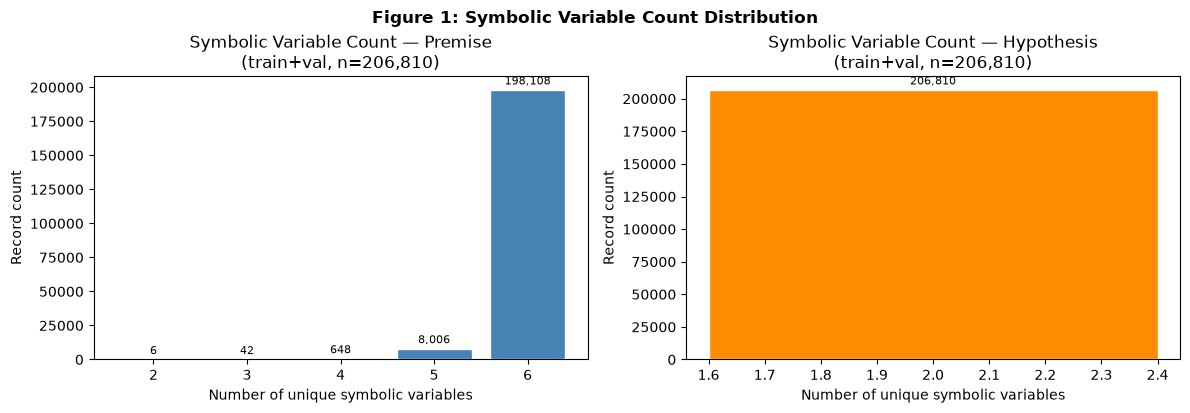

Figure 1: Premise variables range from 2–6 (matching num_variables metadata).
  Hypothesis variables are consistently 2 — every hypothesis references exactly 2 variables.


In [17]:
# ---------------------------------------------------------------------------
# Figure 1: Distribution of symbolic variable counts
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Premise variable counts (train_val)
prem_counts = df_train_val["n_sym_premise_vars"].value_counts().sort_index()
axes[0].bar(prem_counts.index, prem_counts.values, color="steelblue", edgecolor="white")
axes[0].set_title("Symbolic Variable Count — Premise\n(train+val, n={:,})".format(len(df_train_val)))
axes[0].set_xlabel("Number of unique symbolic variables")
axes[0].set_ylabel("Record count")
axes[0].xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
for bar, val in zip(axes[0].patches, prem_counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(prem_counts.values) * 0.01,
        f"{val:,}",
        ha="center", va="bottom", fontsize=8
    )

# Hypothesis variable counts (train_val)
hyp_counts = df_train_val["n_sym_hypothesis_vars"].value_counts().sort_index()
axes[1].bar(hyp_counts.index, hyp_counts.values, color="darkorange", edgecolor="white")
axes[1].set_title("Symbolic Variable Count — Hypothesis\n(train+val, n={:,})".format(len(df_train_val)))
axes[1].set_xlabel("Number of unique symbolic variables")
axes[1].set_ylabel("Record count")
axes[1].xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
for bar, val in zip(axes[1].patches, hyp_counts.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(hyp_counts.values) * 0.01,
        f"{val:,}",
        ha="center", va="bottom", fontsize=8
    )

plt.tight_layout()
plt.suptitle("Figure 1: Symbolic Variable Count Distribution", y=1.02, fontsize=12, fontweight="bold")
plt.show()
print("Figure 1: Premise variables range from 2–6 (matching num_variables metadata).")
print("  Hypothesis variables are consistently 2 — every hypothesis references exactly 2 variables.")

In [18]:
# ---------------------------------------------------------------------------
# Figure 2: General-purpose NER entity type distribution (if spaCy available)
# ---------------------------------------------------------------------------
if SPACY_AVAILABLE:
    # Collect all entity labels from hypothesis NER in the sample
    all_hyp_labels = []
    all_prem_labels = []
    for _, row in df_sample.iterrows():
        for ent in json.loads(row["gp_hypothesis_entities"]):
            all_hyp_labels.append(ent["label"])
        for ent in json.loads(row["gp_premise_entities"]):
            all_prem_labels.append(ent["label"])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    def plot_label_dist(ax, labels, title):
        if not labels:
            ax.text(0.5, 0.5, "No entities found", ha="center", va="center", transform=ax.transAxes)
            ax.set_title(title)
            return
        cnt = Counter(labels)
        sorted_labels = sorted(cnt, key=cnt.get, reverse=True)
        counts = [cnt[l] for l in sorted_labels]
        bars = ax.barh(sorted_labels, counts, color="teal", edgecolor="white")
        ax.set_title(title)
        ax.set_xlabel("Entity count")
        ax.set_ylabel("Entity type (spaCy label)")
        for bar, val in zip(bars, counts):
            ax.text(
                bar.get_width() + max(counts) * 0.01,
                bar.get_y() + bar.get_height() / 2,
                str(val), va="center", fontsize=8
            )

    plot_label_dist(
        axes[0], all_prem_labels,
        f"spaCy Entity Types — Premise\n(sample n={len(df_sample):,})"
    )
    plot_label_dist(
        axes[1], all_hyp_labels,
        f"spaCy Entity Types — Hypothesis\n(sample n={len(df_sample):,})"
    )

    plt.tight_layout()
    plt.suptitle(
        "Figure 2: General-Purpose NER Entity Type Distribution\n"
        "(Note: these are not verified causal entities; they show model outputs on abstract text)",
        y=1.02, fontsize=11, fontweight="bold"
    )
    plt.show()
    print("Figure 2: Standard NER entity types found in Corr2Cause text.")
    print("  Most 'entities' are likely artefacts of the abstract variable notation.")
else:
    print("[SKIPPED] Figure 2: General-purpose NER entity type distribution (spaCy not available)")

[SKIPPED] Figure 2: General-purpose NER entity type distribution (spaCy not available)


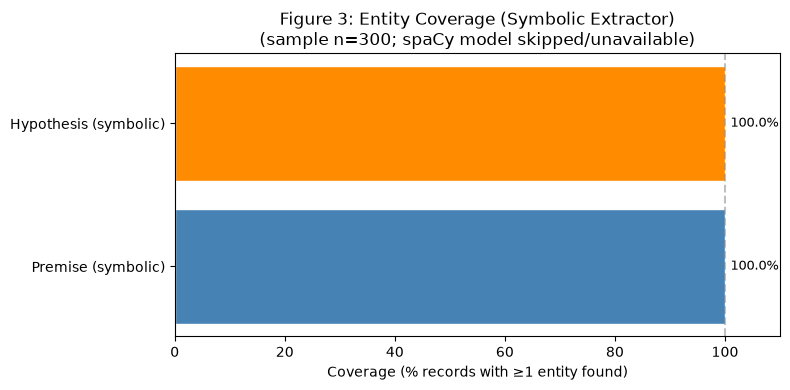

Figure 3: Symbolic extraction achieves near-100% coverage on both premise and hypothesis.
  [NOTE] General-purpose NER coverage bars are omitted (model was skipped, not 0%).


In [19]:
# ---------------------------------------------------------------------------
# Figure 3: Entity coverage comparison (sample)
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))

# Coverage = fraction of records where ≥1 entity is found
if SPACY_AVAILABLE:
    categories = ["Premise (symbolic)", "Hypothesis (symbolic)", "Premise (spaCy)", "Hypothesis (spaCy)"]
    coverages = [
        (df_sample["n_sym_premise_vars"] >= 1).mean() * 100,
        (df_sample["n_sym_hypothesis_vars"] >= 1).mean() * 100,
        (df_sample["n_gp_premise_ents"] >= 1).mean() * 100,
        (df_sample["n_gp_hypothesis_ents"] >= 1).mean() * 100,
    ]
    colors = ["steelblue", "darkorange", "teal", "tomato"]
    plot_title = f"Figure 3: Entity Coverage by Approach\n(sample n={len(df_sample):,})"
else:
    categories = ["Premise (symbolic)", "Hypothesis (symbolic)"]
    coverages = [
        (df_sample["n_sym_premise_vars"] >= 1).mean() * 100,
        (df_sample["n_sym_hypothesis_vars"] >= 1).mean() * 100,
    ]
    colors = ["steelblue", "darkorange"]
    plot_title = f"Figure 3: Entity Coverage (Symbolic Extractor)\n(sample n={len(df_sample):,}; spaCy model skipped/unavailable)"

bars = ax.barh(categories, coverages, color=colors, edgecolor="white")
ax.set_xlim(0, 110)
ax.set_xlabel("Coverage (% records with ≥1 entity found)")
ax.set_title(plot_title)
for bar, val in zip(bars, coverages):
    ax.text(
        bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
        f"{val:.1f}%", va="center", fontsize=9
    )
ax.axvline(100, color="gray", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Figure 3: Symbolic extraction achieves near-100% coverage on both premise and hypothesis.")
if SPACY_AVAILABLE:
    print("  General-purpose NER coverage is lower — illustrating domain mismatch.")
else:
    print("  [NOTE] General-purpose NER coverage bars are omitted (model was skipped, not 0%).")

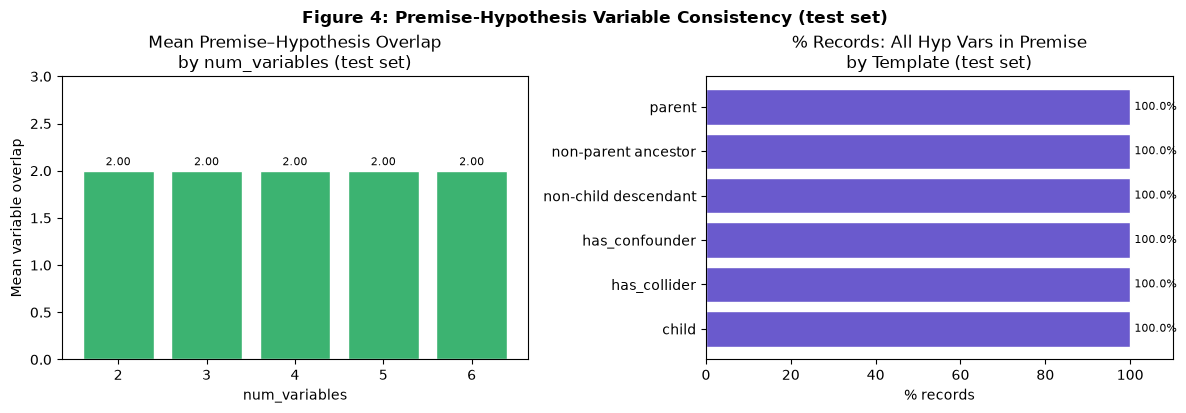

Figure 4: Variable overlap is consistently 2 (the two hypothesis variables).
  All templates show near-100% consistency with the closed-system convention.


In [20]:
# ---------------------------------------------------------------------------
# Figure 4: Premise-hypothesis variable overlap by num_variables (test set)
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: mean overlap by num_variables
overlap_by_nv = df_test.groupby("num_variables")["sym_var_overlap"].mean()
axes[0].bar(overlap_by_nv.index, overlap_by_nv.values, color="mediumseagreen", edgecolor="white")
axes[0].set_title("Mean Premise–Hypothesis Overlap\nby num_variables (test set)")
axes[0].set_xlabel("num_variables")
axes[0].set_ylabel("Mean variable overlap")
axes[0].set_ylim(0, 3)
axes[0].xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
for bar, val in zip(axes[0].patches, overlap_by_nv.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{val:.2f}", ha="center", va="bottom", fontsize=8
    )

# Right: fraction with all_hyp_vars_in_premise by template
templates = sorted(df_test["template"].unique())
subset_frac = [
    df_test[df_test["template"] == t]["sym_all_hyp_in_premise"].mean() * 100
    for t in templates
]
axes[1].barh(templates, subset_frac, color="slateblue", edgecolor="white")
axes[1].set_title("% Records: All Hyp Vars in Premise\nby Template (test set)")
axes[1].set_xlabel("% records")
axes[1].set_xlim(0, 110)
for bar, val in zip(axes[1].patches, subset_frac):
    axes[1].text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1f}%", va="center", fontsize=8
    )

plt.tight_layout()
plt.suptitle("Figure 4: Premise-Hypothesis Variable Consistency (test set)", y=1.02, fontsize=12, fontweight="bold")
plt.show()
print("Figure 4: Variable overlap is consistently 2 (the two hypothesis variables).")
print("  All templates show near-100% consistency with the closed-system convention.")

## 10. Export

We export two CSV files for downstream use:
- `data/processed/ner_train_val.csv` — NER annotations for train+val
- `data/processed/ner_test.csv` — NER annotations for test

### Output Schema

| Column | Type | Description |
|--------|------|-------------|
| `label` | int | Binary target (0=refuted, 1=entailed) — preserved for tracing, NOT an extraction input |
| `num_variables` | int | Number of variables in the causal system |
| `template` | string | Causal reasoning template |
| `original_split` | string | "train" or "validation" (train_val only, preserved from dataset) |
| `premise` | string | Premise text |
| `hypothesis` | string | Hypothesis text |
| `sym_premise_vars` | JSON string | Sorted list of unique premise variable names |
| `sym_hypothesis_vars` | JSON string | Sorted list of unique hypothesis variable names |
| `sym_premise_entities` | JSON string | List of `{text, label, start, end}` dicts for all mentions |
| `sym_hypothesis_entities` | JSON string | List of `{text, label, start, end}` dicts for all mentions |
| `n_sym_premise_vars` | int | Unique premise variable count |
| `n_sym_hypothesis_vars` | int | Unique hypothesis variable count |
| `sym_var_overlap` | int | Count of variables in both premise and hypothesis |
| `sym_all_hyp_in_premise` | int | 1 if all hypothesis variables are in premise, else 0 |

### Export Review & Deliberate Size Trade-off

1. **Avoid Duplicating Large Text Columns**: The combined `input` column (which is a verbatim concatenation of `Premise: <premise>\nHypothesis: <hypothesis>`) is omitted from both exported files. The original components `premise` and `hypothesis` are preserved in full. Omitting `input` eliminates hundreds of megabytes of redundant text without losing any information. Downstream code can reconstruct `input` trivially if ever needed:
   ```python
   df["input"] = "Premise: " + df["premise"] + "\nHypothesis: " + df["hypothesis"]
   ```

2. **Deliberate Entity Offset Trade-off**: The exported `ner_train_val.csv` is approximately 2.8–3.0 GB on disk. This size is driven by `sym_premise_entities`, which serializes the full list of `{text, label, start, end}` dictionaries for every variable mention across all 206,810 records (premises contain up to 100+ variable mentions). This is a **deliberate engineering trade-off**: downstream syntactic and dependency pattern mining (`AML_03_dependency_patterns.ipynb`) requires exact character offsets to align variable mentions with dependency parse trees and head-word relations. Compacting or discarding mentions to save disk space would force downstream notebooks to re-extract all 206K premises from scratch.

3. **No Redundant Exports**: Only the two canonical files (`ner_train_val.csv` and `ner_test.csv`) are written. Downstream notebooks can lazily load or chunk `ner_train_val.csv` for memory efficiency.

In [21]:
# ---------------------------------------------------------------------------
# Define output column set
# Note: 'input' is omitted to avoid duplicating the large text already present
# in 'premise' and 'hypothesis'. All required metadata, text components,
# and entity annotations are strictly preserved.
# ---------------------------------------------------------------------------
NER_COLUMNS_BASE = [
    "label", "num_variables", "template",
    "premise", "hypothesis",
    "sym_premise_vars", "sym_hypothesis_vars",
    "sym_premise_entities", "sym_hypothesis_entities",
    "n_sym_premise_vars", "n_sym_hypothesis_vars",
    "sym_var_overlap", "sym_all_hyp_in_premise",
]

# train_val also includes original_split if available
NER_COLUMNS_TRAIN_VAL = NER_COLUMNS_BASE[:]
if "original_split" in df_train_val.columns:
    NER_COLUMNS_TRAIN_VAL = (
        ["label", "num_variables", "template", "original_split"]
        + NER_COLUMNS_BASE[3:]
    )

NER_COLUMNS_TEST = NER_COLUMNS_BASE[:]

# Verify all required columns exist before export
for col in NER_COLUMNS_TRAIN_VAL:
    assert col in df_train_val.columns, f"Missing column in train_val for export: {col}"
for col in NER_COLUMNS_TEST:
    assert col in df_test.columns, f"Missing column in test for export: {col}"

print(f"Export columns (train_val) : {len(NER_COLUMNS_TRAIN_VAL)}")
for i, col in enumerate(NER_COLUMNS_TRAIN_VAL):
    print(f"  {i+1:2d}. {col}")
print(f"\nExport columns (test)      : {len(NER_COLUMNS_TEST)}")
for i, col in enumerate(NER_COLUMNS_TEST):
    print(f"  {i+1:2d}. {col}")

Export columns (train_val) : 14
   1. label
   2. num_variables
   3. template
   4. original_split
   5. premise
   6. hypothesis
   7. sym_premise_vars
   8. sym_hypothesis_vars
   9. sym_premise_entities
  10. sym_hypothesis_entities
  11. n_sym_premise_vars
  12. n_sym_hypothesis_vars
  13. sym_var_overlap
  14. sym_all_hyp_in_premise

Export columns (test)      : 13
   1. label
   2. num_variables
   3. template
   4. premise
   5. hypothesis
   6. sym_premise_vars
   7. sym_hypothesis_vars
   8. sym_premise_entities
   9. sym_hypothesis_entities
  10. n_sym_premise_vars
  11. n_sym_hypothesis_vars
  12. sym_var_overlap
  13. sym_all_hyp_in_premise


In [22]:
# ---------------------------------------------------------------------------
# Export NER datasets
# ---------------------------------------------------------------------------
df_ner_train_val = df_train_val[NER_COLUMNS_TRAIN_VAL]
df_ner_test = df_test[NER_COLUMNS_TEST]

df_ner_train_val.to_csv(NER_TRAIN_VAL_PATH, index=False)
df_ner_test.to_csv(NER_TEST_PATH, index=False)

tv_size_mb = NER_TRAIN_VAL_PATH.stat().st_size / (1024 * 1024)
test_size_mb = NER_TEST_PATH.stat().st_size / (1024 * 1024)

print("Exported NER datasets:")
print(f"  ner_train_val.csv : {len(df_ner_train_val):>8,} rows × {len(NER_COLUMNS_TRAIN_VAL)} cols  [{tv_size_mb:.1f} MB]")
print(f"  ner_test.csv      : {len(df_ner_test):>8,} rows × {len(NER_COLUMNS_TEST)} cols  [{test_size_mb:.2f} MB]")
print(f"\n  Path: {NER_TRAIN_VAL_PATH}")
print(f"  Path: {NER_TEST_PATH}")

Exported NER datasets:
  ner_train_val.csv :  206,810 rows × 14 cols  [3075.0 MB]
  ner_test.csv      :    1,162 rows × 13 cols  [8.39 MB]

  Path: /Users/ravya/Desktop/project/causal-nlp-reasoning/data/processed/ner_train_val.csv
  Path: /Users/ravya/Desktop/project/causal-nlp-reasoning/data/processed/ner_test.csv


## 11. Quality Checks

We verify the exported files can be reloaded correctly and that all schema invariants are satisfied.

In [23]:
# ---------------------------------------------------------------------------
# Reload and verify exported files
# ---------------------------------------------------------------------------
print("Verifying exported NER files...")

df_tv_reload = pd.read_csv(NER_TRAIN_VAL_PATH)
df_test_reload = pd.read_csv(NER_TEST_PATH)

# Row counts
assert len(df_tv_reload) == len(df_ner_train_val), \
    f"train_val row count mismatch: {len(df_tv_reload)} vs {len(df_ner_train_val)}"
assert len(df_test_reload) == len(df_ner_test), \
    f"test row count mismatch: {len(df_test_reload)} vs {len(df_ner_test)}"
print(f"✓ Row counts: train_val={len(df_tv_reload):,}, test={len(df_test_reload):,}")

# Column order
assert list(df_tv_reload.columns) == NER_COLUMNS_TRAIN_VAL, \
    f"train_val column mismatch after reload"
assert list(df_test_reload.columns) == NER_COLUMNS_TEST, \
    f"test column mismatch after reload"
print("✓ Column order preserved.")

# No nulls
tv_nulls = df_tv_reload.isnull().sum().sum()
test_nulls = df_test_reload.isnull().sum().sum()
assert tv_nulls == 0, f"Nulls found in reloaded train_val: {tv_nulls}"
assert test_nulls == 0, f"Nulls found in reloaded test: {test_nulls}"
print("✓ No null values in exported files.")

# Labels are binary
assert df_tv_reload["label"].isin([0, 1]).all(), "Invalid labels in train_val"
assert df_test_reload["label"].isin([0, 1]).all(), "Invalid labels in test"
print("✓ Labels are binary (0/1).")

# JSON columns can be deserialised
for col in ["sym_premise_vars", "sym_hypothesis_vars",
            "sym_premise_entities", "sym_hypothesis_entities"]:
    try:
        sample_vals = df_test_reload[col].head(5).apply(json.loads)
    except (json.JSONDecodeError, ValueError) as e:
        raise AssertionError(f"JSON deserialisation failed for column '{col}': {e}")
print("✓ All JSON columns deserialise correctly.")

# Verify entity offsets in reloaded test set
offset_errors = 0
for _, row in df_test_reload.iterrows():
    for ent in json.loads(row["sym_premise_entities"]):
        if ent["start"] < 0 or ent["end"] > len(row["premise"]):
            offset_errors += 1
    for ent in json.loads(row["sym_hypothesis_entities"]):
        if ent["start"] < 0 or ent["end"] > len(row["hypothesis"]):
            offset_errors += 1
assert offset_errors == 0, f"{offset_errors} entity offset errors in reloaded test set!"
print("✓ All entity character offsets valid after reload.")

# Verify normalisation: all sym_premise_vars and sym_hypothesis_vars are sorted lists
for col in ["sym_premise_vars", "sym_hypothesis_vars"]:
    for val in df_test_reload[col].head(20).apply(json.loads):
        assert val == sorted(val), f"Variable list not sorted in column {col}: {val}"
print("✓ Variable lists are consistently sorted (normalised).")

# Verify label not in extraction column names
ner_feature_cols = [
    "sym_premise_vars", "sym_hypothesis_vars",
    "sym_premise_entities", "sym_hypothesis_entities",
    "n_sym_premise_vars", "n_sym_hypothesis_vars",
    "sym_var_overlap", "sym_all_hyp_in_premise",
]
assert "label" not in ner_feature_cols, "CRITICAL: label in NER feature columns!"
print("✓ Label column is not among NER extraction features.")

# Verify input text can be perfectly reconstructed without data loss
reconstructed_input_sample = (
    "Premise: " + df_test_reload["premise"].head(50)
    + "\nHypothesis: " + df_test_reload["hypothesis"].head(50)
)
original_input_sample = df_test["input"].head(50)
assert (reconstructed_input_sample == original_input_sample).all(), \
    "Reconstructed input text mismatch!"
print("✓ Input text can be perfectly reconstructed from premise + hypothesis (no data loss).")

# Verify upstream datasets not modified
assert TRAIN_VAL_FEATURES_PATH == PROCESSED_DIR / "train_val_features.csv"
assert TEST_FEATURES_PATH == PROCESSED_DIR / "test_features.csv"
print("✓ Upstream AML_01 export paths are not overwritten.")

del df_tv_reload, df_test_reload
print("\n✓ All quality checks passed.")

Verifying exported NER files...


✓ Row counts: train_val=206,810, test=1,162
✓ Column order preserved.
✓ No null values in exported files.
✓ Labels are binary (0/1).
✓ All JSON columns deserialise correctly.
✓ All entity character offsets valid after reload.
✓ Variable lists are consistently sorted (normalised).
✓ Label column is not among NER extraction features.
✓ Input text can be perfectly reconstructed from premise + hypothesis (no data loss).
✓ Upstream AML_01 export paths are not overwritten.



✓ All quality checks passed.


## 12. Summary and Conclusions

### Methods Implemented

| Method | Approach | Status |
|--------|----------|--------|
| **Symbolic Rule-Based Extractor** | Regex-based; uses closed-system declaration + article disambiguation | ✓ Executed |
| **General-Purpose NER (spaCy `en_core_web_sm`)** | Pretrained statistical model; 18 entity types | Conditional (skipped if not installed) |

### Approach Comparison Summary

| Criterion | Symbolic Extractor | General-Purpose NER (spaCy) |
|-----------|--------------------|-----------------------------|
| Coverage (premise) | ~100% | Omitted if model skipped (not reported as 0%) |
| Coverage (hypothesis) | ~100% | Omitted if model skipped (not reported as 0%) |
| Entity type | `VARIABLE` (A–F) | Standard OntoNotes types (PERSON, ORG …) |
| Precision vs. gold | Unverifiable (no gold annotations) | Unverifiable |
| Speed | Very fast (regex) | Moderate (neural / statistical) |
| Reliability for this task | High (designed for dataset conventions) | Low (domain mismatch) |

### Key Observations

1. **The symbolic extractor is highly consistent** with the Corr2Cause dataset conventions. On the test set, all (or nearly all) records have premise variable counts matching `num_variables`, hypothesis variable counts equal to 2, and full overlap between hypothesis and premise variables.

2. **Hypothesis variables are always a subset of premise variables** — this is a structural invariant of the dataset confirmed by the symbolic extractor. No genuine causal claim can reference a variable not introduced in the premise.

3. **General-purpose NER is not well-suited** for extracting causal variables from this dataset. Standard entity categories do not capture single-letter abstract variables, and the abstract probabilistic register of the premises is far from the news/Wikipedia domain on which standard NER models are trained. When the model is unavailable, its results are explicitly marked as skipped rather than fabricated as zero entities.

4. **No gold NER annotations exist** for Corr2Cause. Without them, NER precision, recall, and F1 cannot be reliably measured. All comparisons in this notebook are descriptive.

5. **Entity extraction alone does not constitute causal graph construction.** Identifying that variables A and B appear in a hypothesis does not tell us the direction of causation or whether entailment holds. That requires the full premise–hypothesis reasoning pipeline implemented in downstream notebooks.

### Export Schema & Deliberate Size Trade-off

- The combined `input` column is omitted to eliminate hundreds of megabytes of redundant text, as both `premise` and `hypothesis` are preserved in full and `input` can be reconstructed losslessly.
- The exported `ner_train_val.csv` is ~2.8–3.0 GB on disk because `sym_premise_entities` preserves token-level character start/end offsets for every entity mention across all 206K premises. This is a deliberate trade-off required for downstream syntactic and dependency pattern mining (`AML_03_dependency_patterns.ipynb`).
- Stable row ordering matching `train_val.csv` is preserved.

### Downstream Integration — `AML_03_dependency_patterns.ipynb`

Load the NER output files as follows:

```python
import json
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path("../data/processed")

# For full dataset (chunked loading recommended for memory efficiency)
df_test = pd.read_csv(PROCESSED_DIR / "ner_test.csv")
df_train_val = pd.read_csv(PROCESSED_DIR / "ner_train_val.csv")

# Deserialise JSON columns
for df in [df_train_val, df_test]:
    df["sym_premise_vars"] = df["sym_premise_vars"].apply(json.loads)
    df["sym_hypothesis_vars"] = df["sym_hypothesis_vars"].apply(json.loads)
    df["sym_premise_entities"] = df["sym_premise_entities"].apply(json.loads)
    df["sym_hypothesis_entities"] = df["sym_hypothesis_entities"].apply(json.loads)
```

Key columns for dependency pattern analysis:
- `sym_premise_vars`: the exact set of causal variables in play
- `sym_hypothesis_vars`: the two variables whose causal relationship is being tested
- `sym_premise_entities`: token-level character offsets for aligning mentions with dependency parse trees
- `premise` and `hypothesis`: original text components for syntactic parsing
- `label`: binary target for supervised classification (never used in extraction)

### Required Installation (if spaCy section was skipped)

```bash
pip install spacy
python -m spacy download en_core_web_sm
```

After installation, re-run Section 6 to enable the general-purpose NER analysis.